# Stock Return Prediction Using Multiple Linear Regression
**Course:** Regression Techniques  |  **Data:** `all_stocks_5yr.csv` (505 stocks, Feb-2013 → Feb-2018)

## Roadmap of this notebook
| # | Section | Course topic covered |
|---|---------|----------------------|
| 1 | Load & clean data | Data quality |
| 2 | Market proxy & feature engineering | Model specification, avoiding look-ahead bias |
| 3 | Exploratory data analysis | Distributions, correlation, linearity |
| 4 | Baseline MLR model | OLS estimation, interpretation, R², adj-R² |
| 5 | Hypothesis tests | t-tests, F-test, general linear hypotheses, robust SEs |
| 6 | Multicollinearity | Correlation, VIF, condition number |
| 7 | Outliers & influential points | Leverage, studentized residuals, Cook's D, DFFITS |
| 8 | Heteroscedasticity | Residual plots, Breusch-Pagan, White, HC3, WLS |
| 9 | Autocorrelation | Durbin-Watson, Breusch-Godfrey, Ljung-Box, HAC |
| 10 | Normality of residuals | Q-Q plot, Jarque-Bera |
| 11 | Model selection | AIC, BIC, adj-R², forward selection |
| 12 | Prediction: CI, PI, accuracy | Confidence/prediction intervals, out-of-sample RMSE/MAE/R², trading-style checks |
| 13 | Stability & conclusions | Sub-period robustness |

> **Key design rules (these make the project credible):**
> 1. Every feature uses information available **at day *t* or earlier**; the response is the **day *t+1*** return → no look-ahead leakage.
> 2. Train/test split is **chronological** (train ≤ 2016, test 2017-2018), never random.
> 3. Expect a **very low R²** (~0–1 %). That is normal — markets are nearly efficient. The marks come from *correct methodology and honest interpretation*, not a high R².

### 1.import libraries & load the Dataset

In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import make_scorer

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson
from scipy import stats

In [13]:
data = pd.read_csv("/content/drive/MyDrive/ML DL AI/Machine Learning Projects/all_stocks_5yr.csv/all_stocks_5yr.csv")
data.head()

,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


### 2. Data Cleaning and Descriptive Overview

In [4]:
df = data.copy()
df.columns = [c.strip().lower() for c in df.columns]
df = df.rename(columns={"name": "ticker"})
required = {"date", "open", "high", "low", "close", "volume", "ticker"}
missing_cols = required - set(df.columns)
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
for c in ["open", "high", "low", "close", "volume"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["ticker"] = df["ticker"].astype("string").str.strip()

print("Rows/columns:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Unique stocks:", df["ticker"].nunique())
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("Exact duplicate rows:", df.duplicated().sum())

# Remove exact duplicates and rows missing required price/date/stock values.
df = df.drop_duplicates()
df = df.dropna(subset=["date", "open", "high", "low", "close", "volume", "ticker"])
df = df.sort_values(["ticker", "date"]).reset_index(drop=True)

# Basic logical checks; flag first, then remove rows with impossible OHLC values.
bad_ohlc = (
    (df[["open", "high", "low", "close"]] <= 0).any(axis=1)
    | (df["high"] < df["low"])
)
print("Rows with invalid/non-positive OHLC:", int(bad_ohlc.sum()))
df = df.loc[~bad_ohlc].copy()

display(df.describe(include="all").T)

Rows/columns: (619040, 7)
Date range: 2013-02-08 00:00:00 to 2018-02-07 00:00:00
Unique stocks: 505

Missing values:


,missing_count
date,0
open,11
high,8
low,8
close,0
volume,0
ticker,0


Exact duplicate rows: 0
Rows with invalid/non-positive OHLC: 1


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,619028,NaN,NaN,NaN,2015-08-18 00:46:34.683278080,2013-02-08 00:00:00,2014-05-20 00:00:00,2015-08-21 00:00:00,2016-11-15 00:00:00,2018-02-07 00:00:00,NaN
open,619028.0,NaN,NaN,NaN,83.02343,1.62,40.22,62.59,94.37,2044.0,97.378819
high,619028.0,NaN,NaN,NaN,83.778516,1.69,40.62,63.15,95.18,2067.99,98.207785
low,619028.0,NaN,NaN,NaN,82.256294,1.5,39.83,62.02,93.54,2035.11,96.507684
close,619028.0,NaN,NaN,NaN,83.0434,1.59,40.2408,62.62,94.41,2049.0,97.388963
volume,619028.0,NaN,NaN,NaN,4321895.770201,101.0,1070351.0,2082165.0,4284551.25,618237630.0,8693677.560958
ticker,619028,505,ZTS,1259,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
data.describe()

,open,high,low,close,volume
count,619029.000000,619032.000000,619032.000000,619040.000000,6.190400e+05
mean,83.023334,83.778311,82.256096,83.043763,4.321823e+06
std,97.378769,98.207519,96.507421,97.389748,8.693610e+06
min,1.620000,1.690000,1.500000,1.590000,0.000000e+00
25%,40.220000,40.620000,39.830000,40.245000,1.070320e+06
50%,62.590000,63.150000,62.020000,62.620000,2.082094e+06
75%,94.370000,95.180000,93.540000,94.410000,4.284509e+06
max,2044.000000,2067.990000,2035.110000,2049.000000,6.182376e+08


## 3. Feature engineering and response variable

For each stock, define:
- **Daily return:** `close_t / close_(t-1) - 1`.
- **Market return proxy:** equal-weighted average of all available stocks' daily returns on date *t*.
- **20-day volatility:** rolling standard deviation of the previous 20 daily returns, including day *t*.
- **20-day momentum:** `close_t / close_(t-20) - 1`.
- **Volume change:** percentage change in volume from the prior observation.
- **High-low spread:** `(high - low) / close`.
- **Next-period return (target):** the next observed daily return for the same stock.

In [14]:
df = df.sort_values(["ticker", "date"]).copy()
df["daily_return"] = df.groupby("ticker")["close"].pct_change()
df["market_return"] = df.groupby("date")["daily_return"].transform("mean")

g = df.groupby("ticker", group_keys=False)
df["volatility_20d"] = g["daily_return"].transform(
    lambda s: s.rolling(window=20, min_periods=20).std()
)
df["momentum_20d"] = g["close"].transform(
    lambda s: s.pct_change(periods=20)
)
df["volume_change"] = g["volume"].transform(
    lambda s: s.pct_change()
)
df["high_low_spread"] = (df["high"] - df["low"]) / df["close"]
df["next_return"] = g["daily_return"].shift(-1)

feature_cols = [
    "daily_return", "market_return", "volatility_20d",
    "momentum_20d", "volume_change", "high_low_spread"
]
model_df = df.replace([np.inf, -np.inf], np.nan).dropna(
    subset=feature_cols + ["next_return", "ticker", "date"]
).copy()

print("Modeling rows:", model_df.shape[0])
print("Stocks:", model_df["ticker"].nunique())
print("Modeling date range:", model_df["date"].min(), "to", model_df["date"].max())
display(model_df[feature_cols + ["next_return"]].describe().T)

Modeling rows: 608423
Stocks: 505
Modeling date range: 2013-03-11 00:00:00 to 2018-02-06 00:00:00


,count,mean,std,min,25%,50%,75%,max
daily_return,608423.0,0.000533,0.016060,-0.626183,-0.006802,0.000622,0.008089,1.009513
market_return,608423.0,0.000531,0.007974,-0.041336,-0.003144,0.000768,0.004933,0.032426
volatility_20d,608423.0,0.014168,0.007535,0.001911,0.009514,0.012449,0.016730,0.256599
momentum_20d,608423.0,0.011439,0.068081,-0.653120,-0.026385,0.011429,0.048649,1.754717
volume_change,608423.0,0.092587,0.593089,-0.950666,-0.219271,-0.011602,0.264221,58.820152
high_low_spread,608423.0,0.019085,0.011993,0.000898,0.011693,0.016060,0.022754,0.875781
next_return,608423.0,0.000529,0.016066,-0.626183,-0.006811,0.000616,0.008089,1.009513


### 4. Multiple Linear Regression
- Multiple Linear Regression (MLR) is a statistical method used to model the relationship between one numerical response variable and multiple predictor variables.
- Its general equation is:

\begin{aligned}
Y_t=\beta_0+\beta_1X_{1,t}+\beta_2X_{2,t}
+\cdots+\beta_6X_{6,t}+\varepsilon_t
\end{aligned}

\
\begin{aligned}
R_{t+1}={}&\beta_0
+\beta_1R_t
+\beta_2R_{m,t}\\
&+\beta_3\sigma_{20,t}
+\beta_4M_{20,t}\\
&+\beta_5VC_t
+\beta_6HL_t
+\varepsilon_t
\end{aligned}


In [19]:
y = df["next_return"]

X = df[
    [
        "daily_return",
        "market_return",
        "volatility_20d",
        "momentum_20d",
        "volume_change",
        "high_low_spread"
    ]
]

dates = np.array(sorted(model_df["date"].unique()))
# Remove rows that cannot be used in the model
model_df = df.dropna(
    subset=feature_cols + ["next_return"]
).copy()

# Inspect the engineered dataset
print("Original observations:", len(df))
print("Usable modeling observations:", len(model_df))

display(
    model_df[
        ["date", "ticker"] + feature_cols + ["next_return"]
    ].head(10)
)

Original observations: 619028
Usable modeling observations: 608423


,date,ticker,daily_return,market_return,volatility_20d,momentum_20d,volume_change,high_low_spread,next_return
20,2013-03-11,A,-0.005113,0.002554,0.015879,-0.050355,0.680691,0.029900,-0.004438
21,2013-03-12,A,-0.004438,-0.002200,0.015771,-0.044395,-0.311580,0.009620,0.008916
22,2013-03-13,A,0.008916,0.004086,0.015956,-0.036307,-0.405171,0.015116,0.007442
23,2013-03-14,A,0.007442,0.005155,0.016058,-0.031955,0.267512,0.008772,-0.007156
24,2013-03-15,A,-0.007156,-0.003039,0.016100,-0.035218,-0.091851,0.007905,-0.010695
25,2013-03-18,A,-0.010695,-0.005640,0.011145,0.007101,-0.283726,0.012221,-0.012926
26,2013-03-19,A,-0.012926,-0.003383,0.010715,-0.023483,2.380538,0.029286,0.016667
27,2013-03-20,A,0.016667,0.008923,0.010655,0.010890,-0.481255,0.013232,-0.024590
28,2013-03-21,A,-0.024590,-0.009110,0.011608,0.000480,0.360697,0.027131,-0.009604
29,2013-03-22,A,-0.009604,0.005633,0.011762,-0.013158,0.230420,0.021333,-0.002909


## 5. Chronological train/test split and multiple linear regression

We reserve the latest 20% of distinct dates for testing. All earlier dates are training data. The model uses numeric features plus ticker fixed effects (one-hot encoding), which allows each stock to have its own intercept. The target remains a return, not a price.

**Evaluation metrics**
- **MAE:** average absolute prediction error.
- **RMSE:** gives larger errors more weight.
- **R²:** fraction of target variation explained relative to predicting the test mean. For return prediction, R² can be near zero or negative even when the model is statistically informative.
- To evaluate generalization, we divide the dataset into:
- Training data: used to estimate the regression coefficients.
- Testing data: used to evaluate predictions on observations that were not used for fitting.

| Period | Purpose |
|---|---|
| 2013–2016 | Training |
| 2017–2018 | Testing |

In [21]:
# Sort the dates chronologically
dates = np.sort(model_df["date"].unique())

# Use the earliest 80% of distinct dates for training
cutoff_index = int(len(dates) * 0.80)
cutoff_date = dates[cutoff_index]

train = model_df[
    model_df["date"] < cutoff_date
].copy()

test = model_df[
    model_df["date"] >= cutoff_date
].copy()

print("Training period:")
print(train["date"].min(), "to", train["date"].max())

print("\nTesting period:")
print(test["date"].min(), "to", test["date"].max())

print("\nTraining observations:", len(train))
print("Testing observations:", len(test))

Training period:
2013-03-11 00:00:00 to 2017-02-10 00:00:00

Testing period:
2017-02-13 00:00:00 to 2018-02-06 00:00:00

Training observations: 483866
Testing observations: 124557


In [22]:
features = [
    "daily_return",
    "market_return",
    "volatility_20d",
    "momentum_20d",
    "volume_change",
    "high_low_spread"
]

X_train = train[features]
y_train = train["next_return"]

X_test = test[features]
y_test = test["next_return"]

In [23]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [24]:
coefficient_table = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})

print("Intercept:", model.intercept_)

display(coefficient_table)

Intercept: -0.00026636037442342693


,Feature,Coefficient
0,daily_return,-0.001410
1,market_return,0.006050
2,volatility_20d,0.047730
3,momentum_20d,-0.004690
4,volume_change,-0.000050
5,high_low_spread,0.008592


In [26]:
predictions = model.predict(X_test)

results = test[
    ["date", "ticker", "next_return"]
].copy()

results["predicted_return"] = predictions

display(results.head(20))

,date,ticker,next_return,predicted_return
1010,2017-02-13,A,-0.002573,2.021783e-04
1011,2017-02-14,A,0.024410,1.134143e-04
1012,2017-02-15,A,-0.015110,1.439965e-04
1013,2017-02-16,A,0.015539,2.248685e-04
1014,2017-02-17,A,-0.005423,1.062418e-04
1015,2017-02-21,A,-0.000195,9.593551e-05
1016,2017-02-22,A,0.002532,1.577279e-05
1017,2017-02-23,A,0.005246,6.612881e-05
1018,2017-02-24,A,-0.001546,8.566589e-07
1019,2017-02-27,A,-0.006969,9.891818e-05


### Evaluation Metrics

In [28]:
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(y_test, predictions)

# Directional accuracy:
# Did the model correctly predict positive/negative return?
directional_accuracy = np.mean(
    np.sign(y_test) == np.sign(predictions)
) * 100

print("\n----- MODEL PERFORMANCE -----")

print(f"MAE: {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R² Score: {r2:.4f}")
print(f"Directional Accuracy: {directional_accuracy:.2f}%")

# Baseline 1: Predict zero return every time
zero_predictions = np.zeros(len(y_test))

zero_mae = mean_absolute_error(y_test, zero_predictions)
zero_rmse = np.sqrt(
    mean_squared_error(y_test, zero_predictions)
)

# Baseline 2: Predict average training return
mean_predictions = np.full(
    len(y_test), y_train.mean()
)

mean_mae = mean_absolute_error(y_test, mean_predictions)
mean_rmse = np.sqrt(
    mean_squared_error(y_test, mean_predictions)
)

print("\n----- BASELINE COMPARISON -----")

print("Linear Regression MAE:", mae)
print("Zero Baseline MAE:", zero_mae)
print("Mean Baseline MAE:", mean_mae)

print("\nLinear Regression RMSE:", rmse)
print("Zero Baseline RMSE:", zero_rmse)
print("Mean Baseline RMSE:", mean_rmse)


----- MODEL PERFORMANCE -----
MAE: 0.009429
RMSE: 0.014697
R² Score: -0.0012
Directional Accuracy: 51.35%

----- BASELINE COMPARISON -----
Linear Regression MAE: 0.009428964140321194
Zero Baseline MAE: 0.009431498452204142
Mean Baseline MAE: 0.009413987606584247

Linear Regression RMSE: 0.0146972111894632
Zero Baseline RMSE: 0.014695613916106985
Mean Baseline RMSE: 0.014688489942297694


## OLS

In [44]:
X_train = sm.add_constant(train[features])
y_train = train['next_return']
ols = sm.OLS(y_train, X_train).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:            next_return   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     92.51
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          1.32e-116
Time:                        19:41:08   Log-Likelihood:             1.3026e+06
No. Observations:              483866   AIC:                        -2.605e+06
Df Residuals:                  483859   BIC:                        -2.605e+06
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -0.0003   5.47e-05     

# 6. Exploratory data analysis (EDA)


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
# import plotly.graph_objects as go

# # Select a stock to plot (e.g., AAPL)
# ticker_to_plot = 'AMZN'
# stock_df = df[df['ticker'] == ticker_to_plot].sort_values('date')

# # Create the interactive candlestick chart
# fig = go.Figure(data=[go.Candlestick(
#     x=stock_df['date'],
#     open=stock_df['open'],
#     high=stock_df['high'],
#     low=stock_df['low'],
#     close=stock_df['close'],
#     name=ticker_to_plot
# )])

# fig.update_layout(
#     title=f'{ticker_to_plot} - 5-Year Candlestick Chart (2013-2018)',
#     yaxis_title='Stock Price (USD)',
#     xaxis_title='Date',
#     xaxis_rangeslider_visible=True,
#     template='plotly_dark'
# )

# fig.show()

Observations by stock (summary):


,observations_per_stock
count,505.000000
mean,1225.798020
std,160.570927
min,44.000000
25%,1259.000000
50%,1259.000000
75%,1259.000000
max,1259.000000


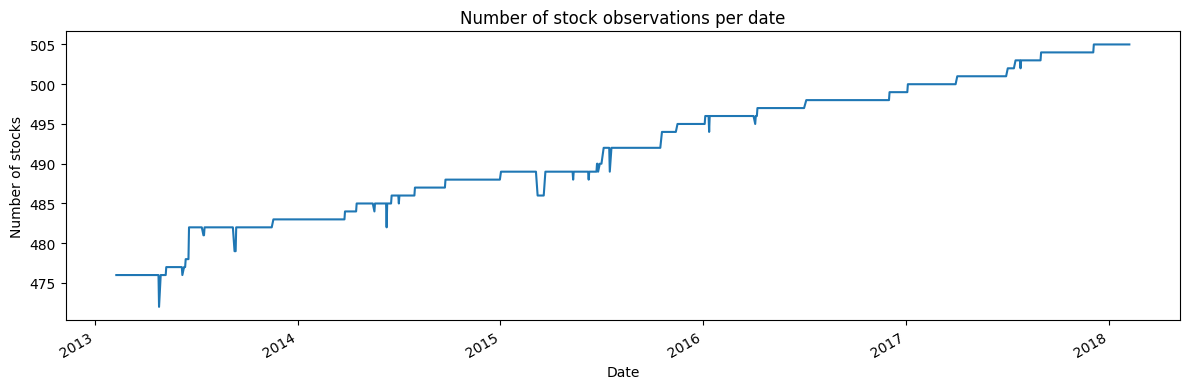

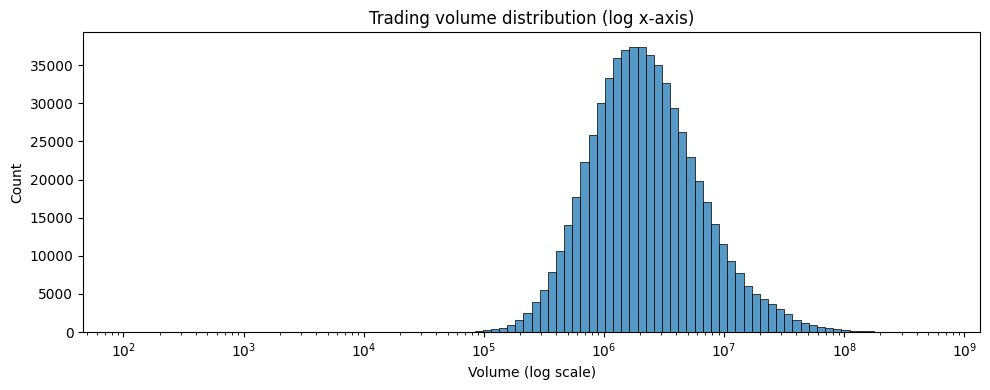

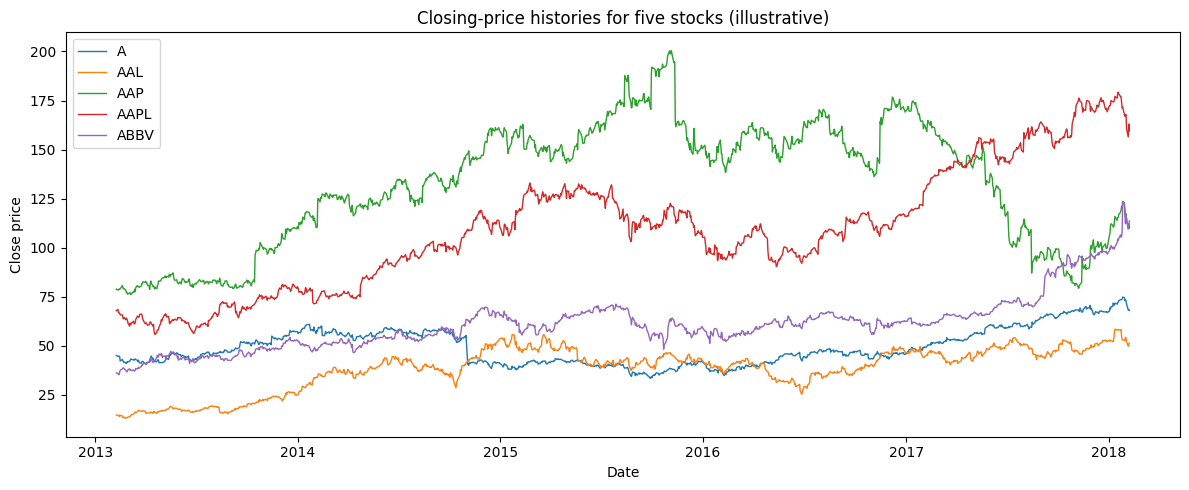

In [30]:
print("Observations by stock (summary):")
obs_by_stock = df.groupby("ticker").size()
display(obs_by_stock.describe().to_frame("observations_per_stock"))

plt.figure(figsize=(12, 4))
df.groupby("date").size().plot()
plt.title("Number of stock observations per date")
plt.xlabel("Date"); plt.ylabel("Number of stocks")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 4))
sns.histplot(df["volume"], bins=100, log_scale=(True, False))
plt.title("Trading volume distribution (log x-axis)")
plt.xlabel("Volume (log scale)")
plt.tight_layout(); plt.show()

# Raw close prices for a small illustrative selection of tickers.
sample_tickers = df["ticker"].drop_duplicates().head(5).tolist()
plt.figure(figsize=(12, 5))
for ticker in sample_tickers:
    s = df.loc[df["ticker"] == ticker]
    plt.plot(s["date"], s["close"], label=ticker, linewidth=1)
plt.title("Closing-price histories for five stocks (illustrative)")
plt.xlabel("Date"); plt.ylabel("Close price")
plt.legend(); plt.tight_layout(); plt.show()

### Graph 1 — Distribution of next-day returns

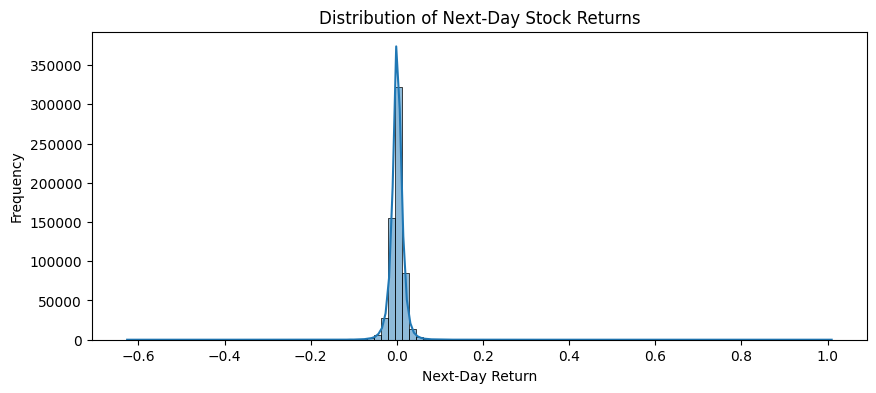

In [42]:
plt.figure(figsize=(10, 4))

sns.histplot(
    df["next_return"],
    bins=100,
    kde=True
)

plt.title("Distribution of Next-Day Stock Returns")
plt.xlabel("Next-Day Return")
plt.ylabel("Frequency")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.show()

### Graph 2 — Average next-day return over time

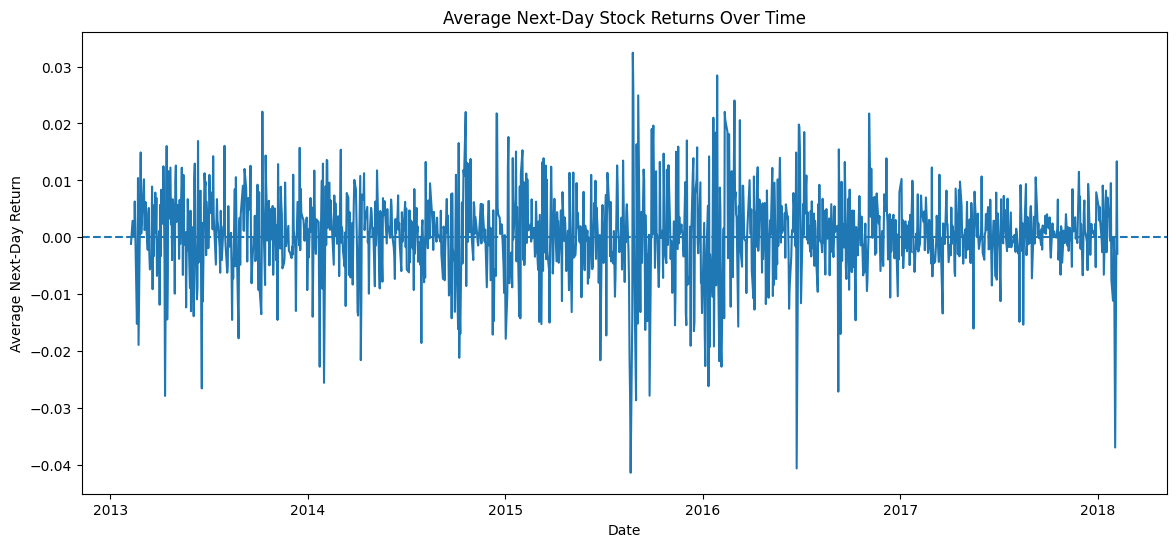

In [36]:
daily_average = (
    df.groupby("date")["next_return"]
    .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_average.index,
    daily_average.values
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Average Next-Day Stock Returns Over Time")
plt.xlabel("Date")
plt.ylabel("Average Next-Day Return")

plt.show()

### Graph 3 — Correlation heatmap

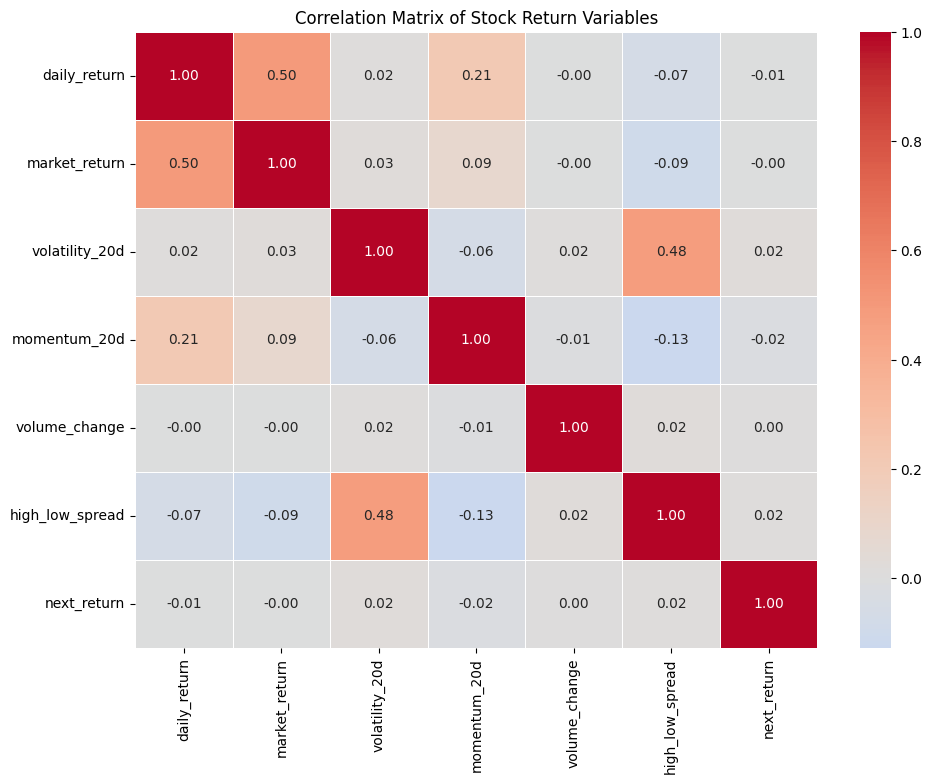

In [37]:
plt.figure(figsize=(11, 8))

corr = df[features + ["next_return"]].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Stock Return Variables")

plt.show()

### Graph 4 — Each independent variable against the target

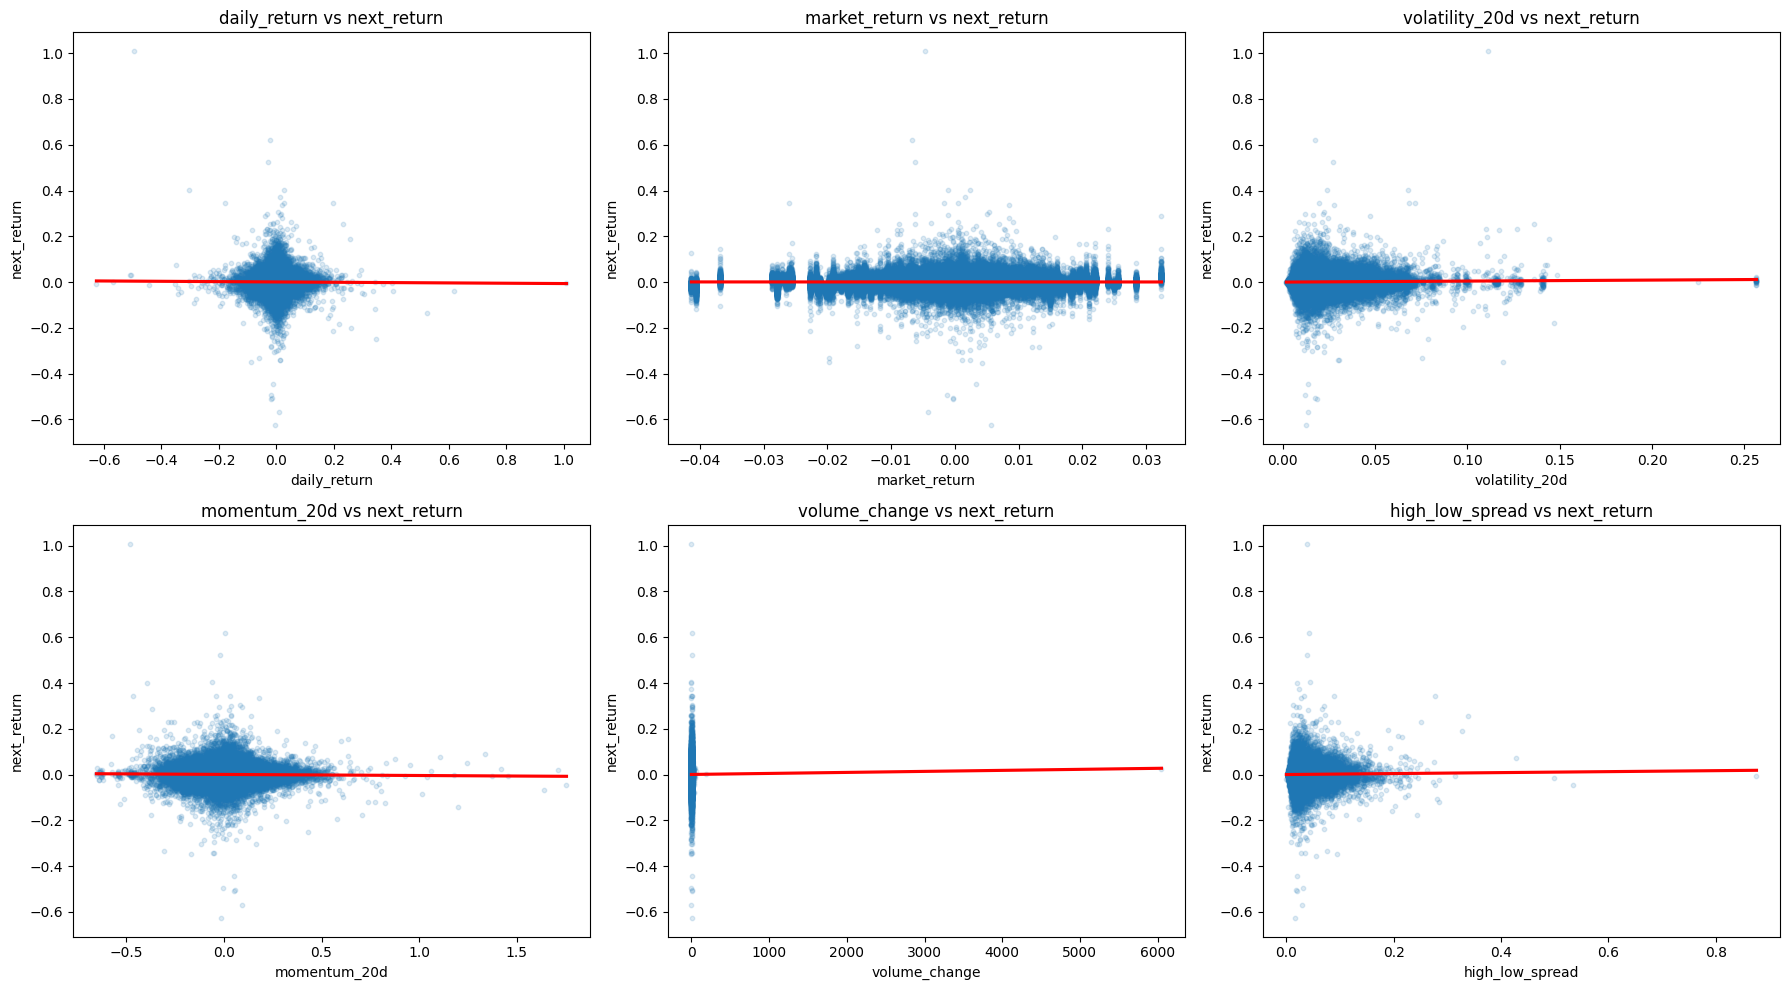

In [40]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10)
)

for feature, ax in zip(features, axes.flatten()):

    sns.regplot(
        data=df,
        x=feature,
        y=df["next_return"],
        ax=ax,
        scatter_kws={"alpha": 0.15, "s": 10},
        line_kws={"color": "red"},
        ci=None
    )

    ax.set_title(f"{feature} vs {"next_return"}")

plt.tight_layout()
plt.show()

### 7. Return distribution, correlations, and outliers

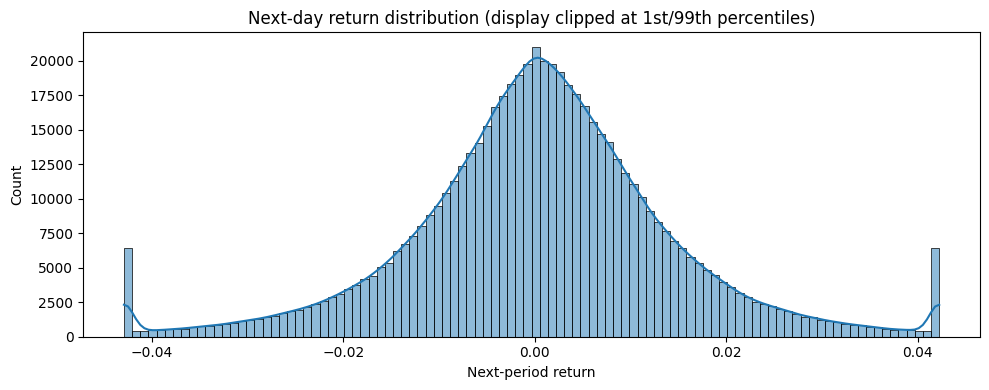

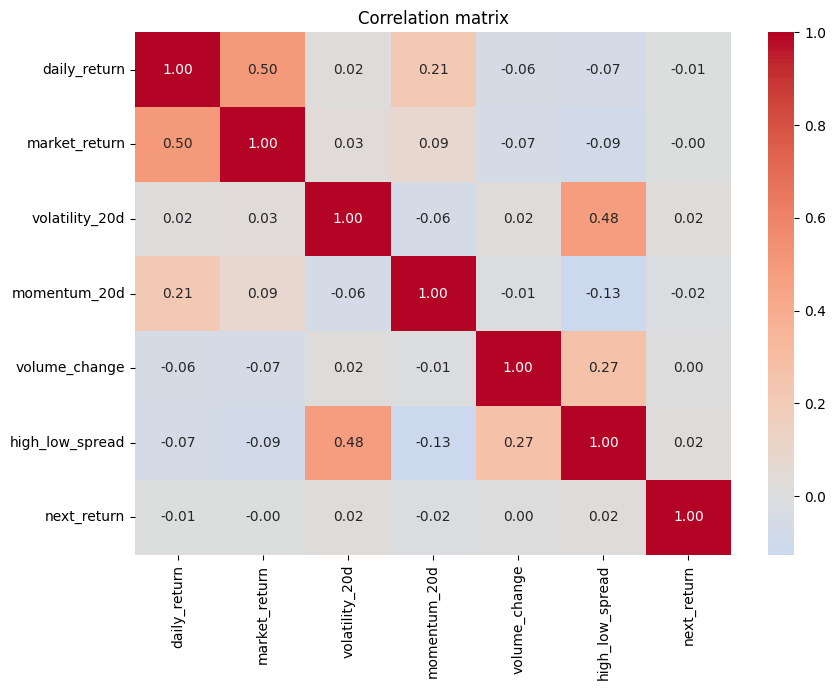

IQR-flagged target observations: 32,894 (5.41%)
Target quantiles:


,next_return
0.000,-0.626183
0.001,-0.090751
0.010,-0.042925
0.250,-0.006811
0.500,0.000616
0.750,0.008089
0.990,0.042244
0.999,0.091912
1.000,1.009513


In [41]:
plt.figure(figsize=(10, 4))
sns.histplot(model_df["next_return"].clip(
    lower=model_df["next_return"].quantile(0.01),
    upper=model_df["next_return"].quantile(0.99)
), bins=100, kde=True)
plt.title("Next-day return distribution (display clipped at 1st/99th percentiles)")
plt.xlabel("Next-period return"); plt.tight_layout(); plt.show()

corr = model_df[feature_cols + ["next_return"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout(); plt.show()

q1, q3 = model_df["next_return"].quantile([0.25, 0.75])
iqr = q3 - q1
outlier_mask = (
    (model_df["next_return"] < q1 - 1.5 * iqr)
    | (model_df["next_return"] > q3 + 1.5 * iqr)
)
print(f"IQR-flagged target observations: {outlier_mask.sum():,} "
      f"({outlier_mask.mean():.2%})")
print("Target quantiles:")
display(model_df["next_return"].quantile([0, .001, .01, .25, .5, .75, .99, .999, 1]))

### 8. Multicollinearity and Variance Inflation Factor (VIF)
- VIF measures how strongly a predictor can be explained by the other predictors. Large VIF values indicate unstable coefficient estimates due to multicollinearity. We calculate VIF for the six numeric predictors, not the hundreds of ticker dummy variables. Rules such as VIF > 5 or > 10 are heuristics, not universal laws.

In [47]:
vif_data = df[features].sample(
    n=min(50000, len(model_df)), random_state=42
).dropna()
# VIF requires a constant for the auxiliary regressions.
vif_X = sm.add_constant(vif_data, has_constant="add")
vif_table = pd.DataFrame({
    "Feature": vif_X.columns,
    "VIF": [variance_inflation_factor(vif_X.values, i)
            for i in range(vif_X.shape[1])]
})
display(vif_table)

,Feature,VIF
0,const,1.000000
1,daily_return,1.397052
2,market_return,1.354669
3,volatility_20d,1.365621
4,momentum_20d,1.061479
5,volume_change,1.107995
6,high_low_spread,1.501670


## 9. Statistical inference, coefficient tests, and confidence intervals

For classical inference, we fit a statsmodels OLS model on a reproducible training sample using numeric predictors. Heteroscedasticity-consistent (HC3) standard errors are reported because return data commonly have non-constant variance. The ticker fixed effects used in the predictive model are excluded from this diagnostic OLS to keep the table readable.

- **Coefficient:** estimated change in expected next-period return for a one-unit increase in a predictor, holding other included predictors fixed.
- **p-value:** tests the null hypothesis that the population coefficient is zero.
- **95% confidence interval:** uncertainty range for a population coefficient under the model assumptions.
- Statistical significance does not guarantee useful out-of-sample prediction.

In [49]:
# Use only training observations and a sample to keep diagnostics tractable.
ols_sample = train.sample(n=min(50000, len(train)), random_state=42)
X_ols = sm.add_constant(ols_sample[features], has_constant="add")
y_ols = ols_sample["next_return"]

ols_model = sm.OLS(y_ols, X_ols).fit()
ols_robust = ols_model.get_robustcov_results(cov_type="HC3")
coef_table = pd.DataFrame({
    "Coefficient": ols_robust.params,
    "Robust_SE_HC3": ols_robust.bse,
    "t_statistic": ols_robust.tvalues,
    "p_value": ols_robust.pvalues,
    "CI_95_lower": ols_robust.conf_int()[:, 0],
    "CI_95_upper": ols_robust.conf_int()[:, 1]
}, index=X_ols.columns)
display(coef_table)
print("Classical OLS R-squared:", ols_model.rsquared)
print("Robust covariance type: HC3")

,Coefficient,Robust_SE_HC3,t_statistic,p_value,CI_95_lower,CI_95_upper
const,-0.000486,0.000325,-1.492121,0.135674,-0.001124,0.000152
daily_return,0.018638,0.009308,2.002238,0.045265,0.000393,0.036882
market_return,0.005919,0.012828,0.461370,0.644535,-0.019225,0.031062
volatility_20d,0.074968,0.019318,3.880769,0.000104,0.037105,0.112831
momentum_20d,-0.005716,0.001667,-3.428782,0.000607,-0.008983,-0.002448
volume_change,-0.000282,0.000175,-1.607000,0.108061,-0.000626,0.000062
high_low_spread,0.004345,0.012183,0.356649,0.721356,-0.019534,0.028224


Classical OLS R-squared: 0.0023845923565330995
Robust covariance type: HC3


### 10. Overall hypothesis test and model selection

In [54]:
print("Overall OLS F-statistic:", ols_model.fvalue)
print("Overall OLS F-test p-value:", ols_model.f_pvalue)

reduced_features = [ "market_return", "volume_change", "high_low_spread"] ## P>=0.05
X_red = sm.add_constant(ols_sample[reduced_features], has_constant="add")
reduced_model = sm.OLS(y_ols, X_red).fit()

selection = pd.DataFrame({
    "Model": ["Full numeric model", "Reduced numeric model"],
    "Predictors": [", ".join(features), ", ".join(reduced_features)],
    "AIC": [ols_model.aic, reduced_model.aic],
    "BIC": [ols_model.bic, reduced_model.bic],
    "In-sample_R2": [ols_model.rsquared, reduced_model.rsquared]
})
display(selection)

# Out-of-sample comparison using same chronological split and numeric-only models.
full_numeric = LinearRegression().fit(train[features], y_train)
red_numeric = LinearRegression().fit(train[reduced_features], y_train)
pred_full_num = full_numeric.predict(test[features])
pred_red_num = red_numeric.predict(test[reduced_features])
comparison = pd.DataFrame({
    "Model": ["Full numeric", "Reduced numeric"],
    "Test_MAE": [
        mean_absolute_error(y_test, pred_full_num),
        mean_absolute_error(y_test, pred_red_num)
    ],
    "Test_RMSE": [
        mean_squared_error(y_test, pred_full_num) ** 0.5,
        mean_squared_error(y_test, pred_red_num) ** 0.5
    ],
    "Test_R2": [
        r2_score(y_test, pred_full_num),
        r2_score(y_test, pred_red_num)
    ]
})
display(comparison)

Overall OLS F-statistic: 19.916313235004143
Overall OLS F-test p-value: 2.220604247629494e-23


,Model,Predictors,AIC,BIC,In-sample_R2
0,Full numeric model,"daily_return, market_return, volatility_20d, m...",-269248.346681,-269186.608233,0.002385
1,Reduced numeric model,"market_return, volume_change, high_low_spread",-269174.148427,-269138.869314,0.000783


,Model,Test_MAE,Test_RMSE,Test_R2
0,Full numeric,0.009429,0.014697,-0.001218
1,Reduced numeric,0.009421,0.014694,-0.000743


## 11. Outlier and influential-observation analysis

Cook's distance and leverage identify observations that may strongly influence the fitted regression. Since the complete dataset is large, this diagnostic is computed on the same OLS sample rather than all rows. Influential observations should be investigated and explained; they should not be deleted automatically. The OLS diagnostic model uses only numeric features.

In [55]:
influence = ols_model.get_influence()
influence_frame = pd.DataFrame({
    "row_index": ols_sample.index,
    "ticker": ols_sample["ticker"].values,
    "date": ols_sample["date"].values,
    "next_return": y_ols.values,
    "fitted": ols_model.fittedvalues.values,
    "residual": ols_model.resid.values,
    "leverage": influence.hat_matrix_diag,
    "cooks_distance": influence.cooks_distance[0]
})
n_ols = len(influence_frame)
p_ols = X_ols.shape[1]
cook_cutoff = 4 / n_ols
leverage_cutoff = 2 * p_ols / n_ols
print(f"Rule-of-thumb Cook's distance cutoff: {cook_cutoff:.6g}")
print(f"Rule-of-thumb leverage cutoff: {leverage_cutoff:.6g}")
print("Cook's distance flags:", int((influence_frame["cooks_distance"] > cook_cutoff).sum()))
print("High-leverage flags:", int((influence_frame["leverage"] > leverage_cutoff).sum()))
display(influence_frame.nlargest(10, "cooks_distance"))

Rule-of-thumb Cook's distance cutoff: 8e-05
Rule-of-thumb leverage cutoff: 0.00028
Cook's distance flags: 2790
High-leverage flags: 3757


,row_index,ticker,date,next_return,fitted,residual,leverage,cooks_distance
6351,116330,CHK,2016-03-03,0.189696,0.014798,0.174897,0.019676,0.333315
20084,116332,CHK,2016-03-07,-0.177820,0.007627,-0.185448,0.007972,0.148269
16501,116328,CHK,2016-03-01,0.231884,0.011542,0.220342,0.004584,0.119555
28806,116339,CHK,2016-03-16,0.091116,0.001956,0.089161,0.011018,0.047660
25946,596450,WMB,2016-01-25,0.115238,0.009556,0.105682,0.005648,0.033957
13947,24178,AGN,2014-02-18,0.045118,-0.003571,0.048689,0.022316,0.029456
12439,62479,ARNC,2016-11-01,-0.051797,0.002071,-0.053868,0.015605,0.024871
18752,40961,AMD,2016-07-22,0.147260,0.004239,0.143021,0.001998,0.021834
49156,213684,EXPE,2013-07-25,-0.273846,-0.000447,-0.273399,0.000512,0.020374
1262,596464,WMB,2016-02-12,0.114328,0.010323,0.104006,0.003489,0.020226


## 12. Heteroscedasticity test

The Breusch–Pagan test checks whether residual variance is associated with the included predictors.

- **H₀:** constant error variance (homoscedasticity).
- **H₁:** error variance depends on one or more predictors (heteroscedasticity).

A small p-value suggests evidence against constant variance. This test can be sensitive in large samples, so pair the result with residual plots and use robust standard errors for inference.

In [56]:
bp_lm, bp_lm_pvalue, bp_f, bp_f_pvalue = het_breuschpagan(
    ols_model.resid, ols_model.model.exog
)
bp_results = pd.DataFrame({
    "Test": ["Breusch-Pagan LM", "Breusch-Pagan F"],
    "Statistic": [bp_lm, bp_f],
    "p_value": [bp_lm_pvalue, bp_f_pvalue]
})
display(bp_results)

,Test,Statistic,p_value
0,Breusch-Pagan LM,1710.755698,0.0
1,Breusch-Pagan F,295.185850,0.0


## 13. Residual independence and autocorrelation

The Durbin–Watson statistic is near 2 when first-order residual autocorrelation is weak; values substantially below 2 suggest positive autocorrelation, and values above 2 suggest negative autocorrelation. However, this pooled sample contains multiple stocks, so a single Durbin–Watson statistic is only a rough diagnostic. The Ljung–Box test below is also applied to the sampled pooled residual sequence and must be interpreted cautiously. A stronger extension would test residual autocorrelation separately for individual stocks.

In [57]:
dw = durbin_watson(ols_model.resid)
print("Durbin-Watson statistic:", dw)

lb = acorr_ljungbox(ols_model.resid, lags=[5, 10], return_df=True)
display(lb)

# Optional stock-specific residual autocorrelation on the sample, for stocks with enough rows.
resid_by_stock = influence_frame.sort_values(["ticker", "date"]).groupby("ticker")["residual"]
stock_dw = []
for ticker, group in influence_frame.sort_values(["ticker", "date"]).groupby("ticker"):
    if len(group) >= 20:
        stock_dw.append((ticker, durbin_watson(group["residual"])))
display(pd.DataFrame(stock_dw, columns=["ticker", "Durbin_Watson"]).head(20))

Durbin-Watson statistic: 1.9939828304664164


,lb_stat,lb_pvalue
5,5.608762,0.346167
10,9.467013,0.488428


,ticker,Durbin_Watson
0,A,2.094154
1,AAL,1.986063
2,AAP,1.737164
3,AAPL,1.989976
4,ABBV,1.550892
5,ABC,1.806769
6,ABT,1.814220
7,ACN,2.248369
8,ADBE,1.766720
9,ADI,2.123689


## 14. Confidence intervals and prediction intervals

A **confidence interval** estimates the mean response for given predictor values. A **prediction interval** estimates the range for an individual future observation and is wider because it includes individual error variation. These intervals come from the numeric OLS diagnostic model and are illustrative; they are not intervals from the ticker-fixed-effect predictive pipeline.

We use a manageable sample of test rows and avoid presenting the interval as a guarantee of future market outcomes.

In [59]:
interval_n = min(1000, len(test))
interval_rows = test.sample(n=interval_n, random_state=42).copy()
X_interval = sm.add_constant(interval_rows[features], has_constant="add")
interval_fit = ols_model.get_prediction(X_interval).summary_frame(alpha=0.05)

interval_output = interval_rows[["date", "ticker", "next_return"]].reset_index(drop=True)
interval_output["mean_prediction"] = interval_fit["mean"].to_numpy()
interval_output["mean_ci_lower"] = interval_fit["mean_ci_lower"].to_numpy()
interval_output["mean_ci_upper"] = interval_fit["mean_ci_upper"].to_numpy()
interval_output["prediction_lower"] = interval_fit["obs_ci_lower"].to_numpy()
interval_output["prediction_upper"] = interval_fit["obs_ci_upper"].to_numpy()
display(interval_output.head(15))

,date,ticker,next_return,mean_prediction,mean_ci_lower,mean_ci_upper,prediction_lower,prediction_upper
0,2017-04-04,BXP,0.002391,0.000273,0.000017,0.000528,-0.031840,0.032385
1,2017-11-14,C,0.002796,0.000034,-0.000180,0.000249,-0.032078,0.032147
2,2017-06-21,MAS,0.001548,-0.000262,-0.000506,-0.000018,-0.032374,0.031850
3,2017-05-10,CSX,0.008121,0.000228,-0.000063,0.000519,-0.031885,0.032340
4,2017-10-18,UTX,0.002601,-0.000187,-0.000414,0.000040,-0.032299,0.031925
5,2017-04-17,IT,-0.003248,0.000520,0.000244,0.000795,-0.031593,0.032632
6,2017-07-13,ABT,0.017263,-0.000187,-0.000471,0.000098,-0.032299,0.031926
7,2017-12-13,F,-0.013460,0.000075,-0.000161,0.000312,-0.032037,0.032188
8,2017-09-08,ANTM,0.010833,0.000257,0.000073,0.000440,-0.031855,0.032369
9,2017-05-22,TAP,-0.003362,0.000845,0.000639,0.001051,-0.031267,0.032957


## 15. Summary table and automatic interpretation prompts

This section gathers the main test metrics and diagnostics into a compact report. The text printed below is a template based on the computed outputs. Interpret all results in context: financial returns are noisy, the benchmark here is an equal-weighted proxy, and historical performance does not establish a profitable trading strategy.

In [61]:
summary = {
    "Rows_after_feature_engineering": len(model_df),
    "Number_of_stocks": model_df["ticker"].nunique(),
    "Train_rows": len(train),
    "Test_rows": len(test),
    "Test_MAE": mean_absolute_error(y_test, predictions),
    "Test_RMSE": mean_squared_error(y_test, predictions) ** 0.5,
    "Test_R2": r2_score(y_test, predictions),
    "Baseline_test_MAE": mean_absolute_error(y_test, np.repeat(y_train.mean(), len(y_test))),
    "OLS_sample_R2": ols_model.rsquared,
    "OLS_robust_HC3_F_pvalue": float(ols_model.f_pvalue),
    "Durbin_Watson_pooled_sample": float(dw),
    "Breusch_Pagan_LM_pvalue": float(bp_lm_pvalue),
}
display(pd.DataFrame({"Result": summary}).T)

print("\nHow to write the conclusion:")
print("- Report the chronological test period and compare model MAE/RMSE with the mean-return baseline.")
print("- State whether test R-squared is positive or negative; do not describe a negative R-squared as good fit.")
print("- Discuss coefficient signs and HC3 p-values, while separating statistical significance from predictive usefulness.")
print("- Report VIF, Breusch-Pagan, Durbin-Watson/Ljung-Box, and influence diagnostics.")
print("- Explicitly state that market_return is an equal-weighted proxy, not S&P 500.")

,Rows_after_feature_engineering,Number_of_stocks,Train_rows,Test_rows,Test_MAE,Test_RMSE,Test_R2,Baseline_test_MAE,OLS_sample_R2,OLS_robust_HC3_F_pvalue,Durbin_Watson_pooled_sample,Breusch_Pagan_LM_pvalue
Result,608423.0,505.0,483866.0,124557.0,0.009429,0.014697,-0.001218,0.009414,0.002385,2.220604e-23,1.993983,0.0



How to write the conclusion:
- Report the chronological test period and compare model MAE/RMSE with the mean-return baseline.
- State whether test R-squared is positive or negative; do not describe a negative R-squared as good fit.
- Discuss coefficient signs and HC3 p-values, while separating statistical significance from predictive usefulness.
- Report VIF, Breusch-Pagan, Durbin-Watson/Ljung-Box, and influence diagnostics.
- Explicitly state that market_return is an equal-weighted proxy, not S&P 500.
